<a href="https://colab.research.google.com/github/sumaiyakhanum-py/CodeAlpha_FAQ_Chatbot/blob/main/Object_Detection_Tracking.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install ultralytics opencv-python-headless

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 21.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 4.5 MB/s eta 0:00:00


In [3]:

import os

for root, dirs, files_found in os.walk("/content"):
    for name in files_found:
        if name.lower().endswith((".mp4", ".avi", ".mov")):
            print(os.path.join(root, name))

In [5]:
from google.colab import files

uploaded = files.upload()

Saving VN20261008_195201.mp4 to VN20261008_195201.mp4


In [6]:

from ultralytics import YOLO
import torch
import os

video_path = "/content/VN20261008_195201.mp4"

print("Video exists:", os.path.exists(video_path))
print("GPU available:", torch.cuda.is_available())

model = YOLO("yolo11n.pt")

results = model.track(
    source=video_path,
    tracker="bytetrack.yaml",
    save=True,
    show=False,
    conf=0.25,
    imgsz=320,
    device="cpu",
    vid_stride=2,
    stream=True
)

for result in results:
    pass

print("Object detection and tracking completed!")

Video exists: True
GPU available: False

video 1/1 (frame 1/154) /content/VN20261008_195201.mp4: 320x160 5 cars, 1 bus, 271.7ms
video 1/1 (frame 2/154) /content/VN20261008_195201.mp4: 320x160 5 cars, 1 bus, 61.4ms
video 1/1 (frame 3/154) /content/VN20261008_195201.mp4: 320x160 5 cars, 1 bus, 48.4ms
video 1/1 (frame 4/154) /content/VN20261008_195201.mp4: 320x160 5 cars, 2 buss, 33.2ms
video 1/1 (frame 5/154) /content/VN20261008_195201.mp4: 320x160 5 cars, 3 buss, 48.2ms
video 1/1 (frame 6/154) /content/VN20261008_195201.mp4: 320x160 5 cars, 3 buss, 37.5ms
video 1/1 (frame 7/154) /content/VN20261008_195201.mp4: 320x160 5 cars, 3 buss, 32.6ms
video 1/1 (frame 8/154) /content/VN20261008_195201.mp4: 320x160 5 cars, 3 buss, 32.3ms
video 1/1 (frame 9/154) /content/VN20261008_195201.mp4: 320x160 5 cars, 3 buss, 32.8ms
video 1/1 (frame 10/154) /content/VN20261008_195201.mp4: 320x160 5 cars, 3 buss, 32.7ms
video 1/1 (frame 11/154) /content/VN20261008_195201.mp4: 320x160 5 cars, 3 buss, 33.6ms
vi

In [7]:

import os

for root, dirs, files in os.walk("/content/runs"):
    for name in files:
        if name.lower().endswith((".avi", ".mp4")):
            path = os.path.join(root, name)
            print("Output video:", path)
            print("File size:", os.path.getsize(path), "bytes")

Output video: /content/runs/detect/track/VN20261008_195201.avi
File size: 8161040 bytes


In [16]:

import cv2
import os

input_video = "/content/runs/detect/track/VN20261008_195201.avi"
output_mp4 = "/content/tracked_output.mp4"

cap = cv2.VideoCapture(input_video)

if not cap.isOpened():
    print("Video not found. Check the output path.")
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    writer = cv2.VideoWriter(
        output_mp4,
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps if fps > 0 else 15,
        (width, height)
    )

    count = 0

    while True:
        ret, frame = cap.read()
        if not ret:
            break
        writer.write(frame)
        count += 1

    cap.release()
    writer.release()

    print("Frames converted:", count)
    print("MP4 created:", os.path.exists(output_mp4))
    print("File size:", os.path.getsize(output_mp4), "bytes")

Frames converted: 154
MP4 created: True
File size: 4006773 bytes


In [17]:

import os

for root, dirs, files_found in os.walk("/content"):
    for name in files_found:
        if name.lower().endswith((".mp4", ".avi", ".mov")):
            print(os.path.join(root, name))

/content/tracked_output.mp4
/content/VN20261008_195201.mp4
/content/runs/detect/track/VN20261008_195201.avi


In [18]:

from IPython.display import Video, display

display(Video("/content/tracked_output.mp4", embed=True))

In [19]:

!ffmpeg -y -i /content/tracked_output.mp4 -vcodec libx264 -pix_fmt yuv420p -movflags +faststart -an /content/tracked_output_fixed.mp4

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [20]:
from IPython.display import Video, display

display(Video("/content/tracked_output_fixed.mp4", embed=True, width=400))

File exists: True
File size: 8161040 bytes
Video opened: True
Frame count: 154
FPS: 15.0
First frame read: True


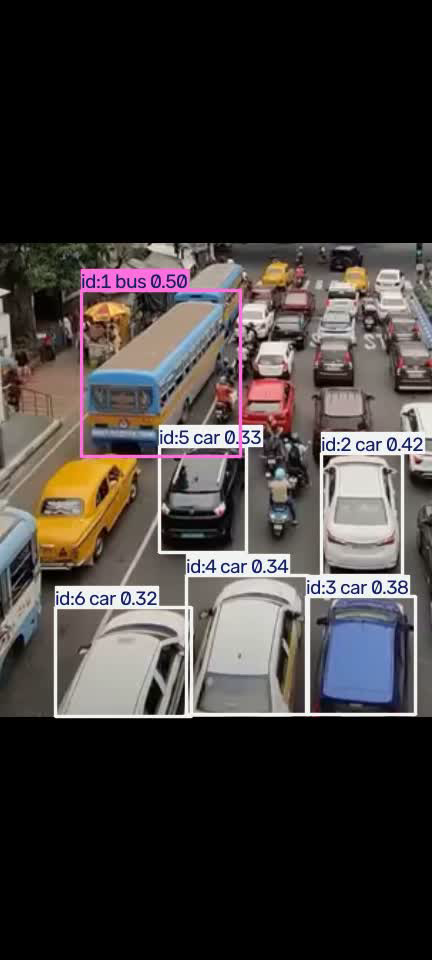

In [11]:

import os
import cv2

video_path = "/content/runs/detect/track/VN20261008_195201.avi"

print("File exists:", os.path.exists(video_path))

if os.path.exists(video_path):
    print("File size:", os.path.getsize(video_path), "bytes")

    cap = cv2.VideoCapture(video_path)
    print("Video opened:", cap.isOpened())
    print("Frame count:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
    print("FPS:", cap.get(cv2.CAP_PROP_FPS))

    ret, frame = cap.read()
    print("First frame read:", ret)

    if ret:
        from google.colab.patches import cv2_imshow
        cv2_imshow(frame)

    cap.release()

In [12]:

import os

for folder in [
    "/content/runs/detect",
    "/content/runs/track",
    "/content/runs"
]:
    print("\nChecking:", folder)

    if os.path.exists(folder):
        for root, dirs, files in os.walk(folder):
            for name in files:
                if name.lower().endswith((".avi", ".mp4", ".mov")):
                    path = os.path.join(root, name)
                    print("VIDEO:", path)
                    print("SIZE:", os.path.getsize(path), "bytes")
    else:
        print("Folder does not exist")


Checking: /content/runs/detect
VIDEO: /content/runs/detect/track/VN20261008_195201.avi
SIZE: 8161040 bytes

Checking: /content/runs/track
Folder does not exist

Checking: /content/runs
VIDEO: /content/runs/detect/track/VN20261008_195201.avi
SIZE: 8161040 bytes
